In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("/Online Retail.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
print("Dataset shape:", df.shape)

display(df.head())

df.info()

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [3]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check numerical summaries
display(df[["Quantity", "UnitPrice"]].describe())

# Check date range
print("\nStart date:", df["InvoiceDate"].min())
print("End date:", df["InvoiceDate"].max())

# Check number of unique customers and invoices
print("\nUnique customers:", df["CustomerID"].nunique())
print("Unique invoices:", df["InvoiceNo"].nunique())

Missing values per column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268


,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000



Start date: 2010-12-01 08:26:00
End date: 2011-12-09 12:50:00

Unique customers: 4372
Unique invoices: 25900


In [4]:
# Check negative and zero values
print("Negative quantity rows:", (df["Quantity"] < 0).sum())
print("Zero quantity rows:", (df["Quantity"] == 0).sum())

print("Negative price rows:", (df["UnitPrice"] < 0).sum())
print("Zero price rows:", (df["UnitPrice"] == 0).sum())

# Check cancellation invoices
cancelled = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Rows with cancellation invoice prefix:", len(cancelled))

# Inspect negative-price records
display(df[df["UnitPrice"] < 0].head(10))

# Inspect negative-quantity records
display(df[df["Quantity"] < 0].head(10))

Negative quantity rows: 10624
Zero quantity rows: 0
Negative price rows: 2
Zero price rows: 2515
Rows with cancellation invoice prefix: 9288


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [5]:
# Preserve the original dataset
df_raw = df.copy()

# Remove exact duplicate rows from the analysis copy
df_clean = df_raw.drop_duplicates().copy()

print("Original rows:", len(df_raw))
print("Rows after removing duplicates:", len(df_clean))
print("Duplicates remaining:", df_clean.duplicated().sum())

Original rows: 541909
Rows after removing duplicates: 536641
Duplicates remaining: 0


In [6]:
# Calculate signed line revenue
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Flag cancellation invoices
df_clean["IsCancellation"] = (
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
)

# Flag records with missing customer IDs
df_clean["MissingCustomerID"] = df_clean["CustomerID"].isna()

# Extract date components
df_clean["YearMonth"] = (
    df_clean["InvoiceDate"].dt.to_period("M").astype(str)
)

display(df_clean.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,IsCancellation,MissingCustomerID,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,False,False,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,False,False,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,False,False,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,False,False,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,False,False,2010-12


In [7]:
print("Total line revenue:", round(df_clean["Revenue"].sum(), 2))

print(
    "Revenue from non-cancellation invoices:",
    round(df_clean.loc[~df_clean["IsCancellation"], "Revenue"].sum(), 2)
)

print(
    "Unique customers:",
    df_clean["CustomerID"].nunique()
)

print(
    "Unique invoices:",
    df_clean["InvoiceNo"].nunique()
)

Total line revenue: 9726006.95
Revenue from non-cancellation invoices: 10619986.68
Unique customers: 4372
Unique invoices: 25900


,Revenue
YearMonth,
2010-12,746723.610
2011-01,558448.560
2011-02,497026.410
2011-03,682013.980
2011-04,492367.841
2011-05,722094.100
2011-06,689977.230
2011-07,680156.991
2011-08,681386.460


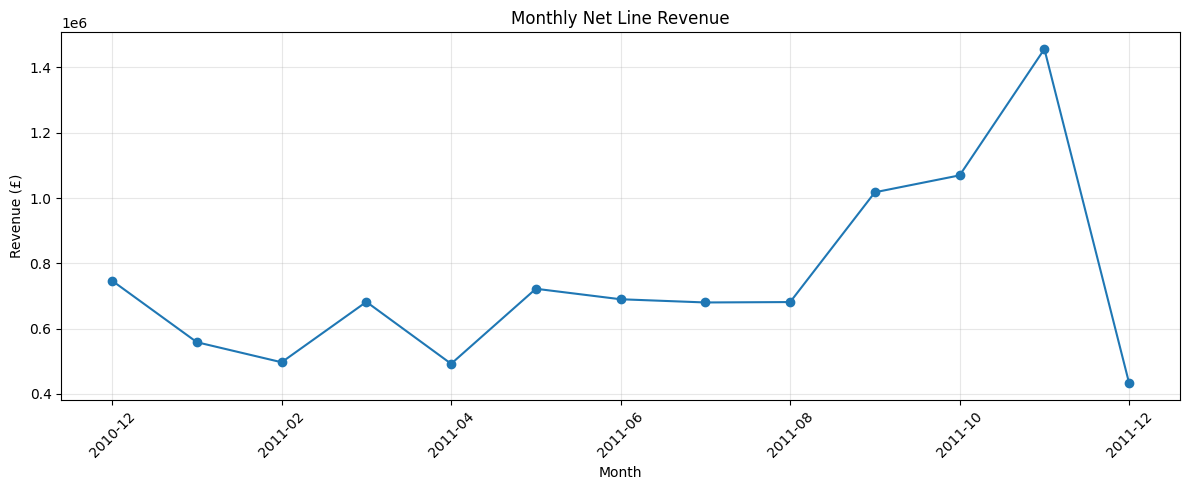

In [8]:
# Revenue by month, including all signed line values
monthly_revenue = (
    df_clean.groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

display(monthly_revenue)

# Plot monthly revenue
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
monthly_revenue.plot(kind="line", marker="o")
plt.title("Monthly Net Line Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
best_month = monthly_revenue.idxmax()
best_revenue = monthly_revenue.max()

lowest_month = monthly_revenue.idxmin()
lowest_revenue = monthly_revenue.min()

print("Highest revenue month:", best_month)
print("Revenue:", round(best_revenue, 2))

print("\nLowest revenue month:", lowest_month)
print("Revenue:", round(lowest_revenue, 2))

Highest revenue month: 2011-11
Revenue: 1456145.8

Lowest revenue month: 2011-12
Revenue: 432701.06


In [10]:
# Exclude cancellation invoices for this preliminary product analysis
sales_df = df_clean[
    ~df_clean["IsCancellation"]
].copy()

# Calculate revenue by product description
top_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products)

,Revenue
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78101.88
Manual,77752.82


In [11]:
country_revenue = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

display(country_revenue.head(10))

,Revenue
Country,
United Kingdom,8979619.974
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340


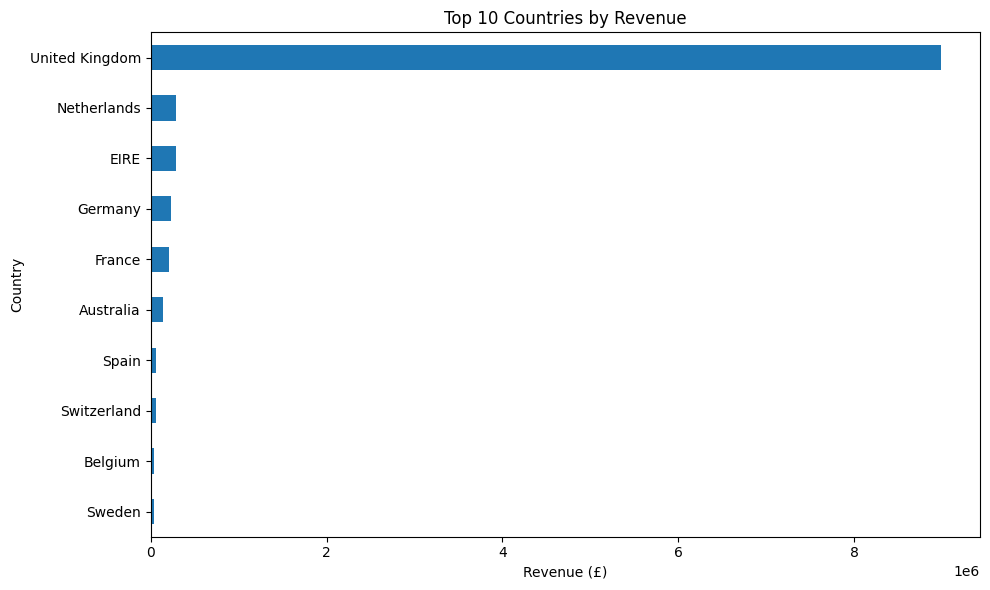

In [12]:
import matplotlib.pyplot as plt

top_countries = country_revenue.head(10).sort_values()

plt.figure(figsize=(10, 6))
top_countries.plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [13]:
# Keep records with known customer IDs
customer_df = sales_df[
    sales_df["CustomerID"].notna()
].copy()

# Revenue by customer
customer_revenue = (
    customer_df.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Unique identified customers:", customer_revenue.size)

print(
    "Average revenue per customer:",
    round(customer_revenue.mean(), 2)
)

print(
    "Median revenue per customer:",
    round(customer_revenue.median(), 2)
)

print("\nTop 10 customers by revenue:")
display(customer_revenue.head(10))

Unique identified customers: 4339
Average revenue per customer: 2048.22
Median revenue per customer: 668.56

Top 10 customers by revenue:


,Revenue
CustomerID,
14646.0,280206.02
18102.0,259657.30
17450.0,194390.79
16446.0,168472.50
14911.0,143711.17
12415.0,124914.53
14156.0,117210.08
17511.0,91062.38
16029.0,80850.84


In [14]:
customer_orders = (
    customer_df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

repeat_customers = (customer_orders > 1).sum()
total_customers = customer_orders.size

repeat_rate = repeat_customers / total_customers * 100

print("Total customers:", total_customers)
print("Repeat customers:", repeat_customers)
print(f"Repeat-customer rate: {repeat_rate:.2f}%")

Total customers: 4339
Repeat customers: 2845
Repeat-customer rate: 65.57%


In [15]:
import pandas as pd

# Use records with identified customers
rfm_source = customer_df.copy()

reference_date = rfm_source["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = rfm_source.groupby("CustomerID").agg(
    Recency=("InvoiceDate",
             lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
)

display(rfm.head())

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [17]:
rfm["Segment"] = "Regular"

rfm.loc[
    (rfm["Frequency"] >= 5) & (rfm["Monetary"] > 1000),
    "Segment"
] = "High-value repeat"

rfm.loc[
    (rfm["Recency"] > 90),
    "Segment"
] = "At-risk"

print(rfm["Segment"].value_counts())

Segment
Regular              1917
At-risk              1449
High-value repeat     973
Name: count, dtype: int64


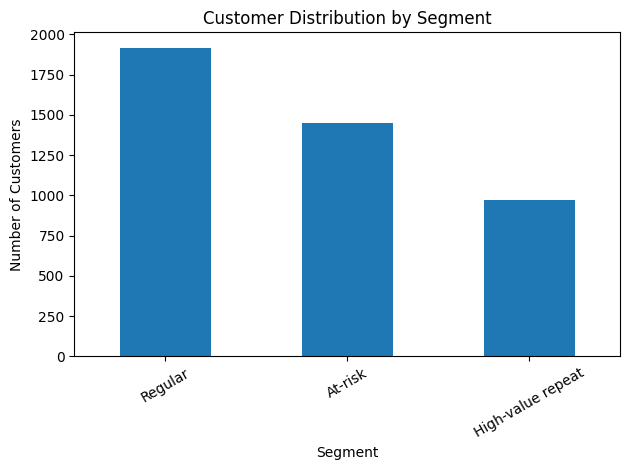

In [18]:
import matplotlib.pyplot as plt

rfm["Segment"].value_counts().plot(kind="bar")

plt.title("Customer Distribution by Segment")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [19]:
segment_summary = rfm.groupby("Segment").agg(
    Customers=("Recency", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Revenue=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

display(segment_summary)

,Customers,Avg_Recency,Avg_Frequency,Avg_Revenue,Total_Revenue
Segment,,,,,
At-risk,1449,213.61,1.86,712.59,1032542.29
High-value repeat,973,20.35,11.71,6291.90,6122023.35
Regular,1917,37.62,2.32,903.83,1732643.25


In [20]:
segment_summary["Revenue_Share_%"] = (
    segment_summary["Total_Revenue"]
    / segment_summary["Total_Revenue"].sum()
    * 100
).round(2)

display(segment_summary)

,Customers,Avg_Recency,Avg_Frequency,Avg_Revenue,Total_Revenue,Revenue_Share_%
Segment,,,,,,
At-risk,1449,213.61,1.86,712.59,1032542.29,11.62
High-value repeat,973,20.35,11.71,6291.90,6122023.35,68.89
Regular,1917,37.62,2.32,903.83,1732643.25,19.50


In [21]:
print("Rows after deduplication:", len(df_clean))

print("Cancelled invoice rows:", df_clean["IsCancellation"].sum())

print("Negative quantity rows:", (df_clean["Quantity"] < 0).sum())

print("Zero-price rows:", (df_clean["UnitPrice"] == 0).sum())

print("Negative-price rows:", (df_clean["UnitPrice"] < 0).sum())

Rows after deduplication: 536641
Cancelled invoice rows: 9251
Negative quantity rows: 10587
Zero-price rows: 2510
Negative-price rows: 2


In [22]:
sales_valid = df_clean[
    (~df_clean["IsCancellation"]) &
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

sales_valid["Revenue"] = (
    sales_valid["Quantity"] * sales_valid["UnitPrice"]
)

print("Valid positive-sales rows:", len(sales_valid))
print("Unique invoices:", sales_valid["InvoiceNo"].nunique())
print("Unique identified customers:", sales_valid["CustomerID"].nunique())
print("Total positive-sales revenue: £",
      round(sales_valid["Revenue"].sum(), 2))

Valid positive-sales rows: 524878
Unique invoices: 19960
Unique identified customers: 4338
Total positive-sales revenue: £ 10642110.8


In [23]:
# 1. Monthly revenue
monthly_sales = sales_valid.groupby("YearMonth")["Revenue"].sum()

print("Best month:", monthly_sales.idxmax())
print("Best-month revenue: £", round(monthly_sales.max(), 2))

# 2. Top 10 products/descriptions
print("\nTop 10 descriptions by revenue:")
display(
    sales_valid.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# 3. Top 10 countries
print("\nTop 10 countries by revenue:")
display(
    sales_valid.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

Best month: 2011-11
Best-month revenue: £ 1503866.78

Top 10 descriptions by revenue:


,Revenue
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78101.88
Manual,77752.82



Top 10 countries by revenue:


,Revenue
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340


In [24]:
# Cancellation and return analysis
cancelled = df_clean[df_clean["IsCancellation"]].copy()

returns = df_clean[
    (df_clean["Quantity"] < 0) &
    (~df_clean["IsCancellation"])
].copy()

print("Cancelled invoice rows:", len(cancelled))
print("Cancelled invoices:", cancelled["InvoiceNo"].nunique())
print("Revenue recorded on cancellation rows: £",
      round(cancelled["Revenue"].sum(), 2))

print("\nNegative-quantity rows outside cancelled invoices:", len(returns))
print("Return value (absolute): £",
      round(returns["Revenue"].abs().sum(), 2))

Cancelled invoice rows: 9251
Cancelled invoices: 3836
Revenue recorded on cancellation rows: £ -893979.73

Negative-quantity rows outside cancelled invoices: 1336
Return value (absolute): £ 0.0


In [25]:
returns = df_clean[
    (df_clean["Quantity"] < 0) &
    (~df_clean["IsCancellation"])
].copy()

print("Unit price distribution:")
display(returns["UnitPrice"].describe())

print("\nRows with zero unit price:",
      (returns["UnitPrice"] == 0).sum())

print("\nSample records:")
display(
    returns[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue", "Country"]
    ].head(10)
)

Unit price distribution:


,UnitPrice
count,1336.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0



Rows with zero unit price: 1336

Sample records:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue,Country
2406,536589,21777,NaN,-10,0.0,-0.0,United Kingdom
4347,536764,84952C,NaN,-38,0.0,-0.0,United Kingdom
7188,536996,22712,NaN,-20,0.0,-0.0,United Kingdom
7189,536997,22028,NaN,-20,0.0,-0.0,United Kingdom
7190,536998,85067,NaN,-6,0.0,-0.0,United Kingdom
7192,537000,21414,NaN,-22,0.0,-0.0,United Kingdom
7193,537001,21653,NaN,-6,0.0,-0.0,United Kingdom
7195,537003,85126,NaN,-2,0.0,-0.0,United Kingdom
7196,537004,21814,NaN,-30,0.0,-0.0,United Kingdom
7197,537005,21692,NaN,-70,0.0,-0.0,United Kingdom


In [26]:
non_merchandise = [
    "DOTCOM POSTAGE",
    "POSTAGE",
    "Manual"
]

merchandise = sales_valid[
    sales_valid["Description"].notna() &
    (~sales_valid["Description"].str.strip().str.upper()
      .isin(non_merchandise))
].copy()

top_merchandise = (
    merchandise.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_merchandise)

,Revenue
Description,
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
Manual,77752.82
RABBIT NIGHT LIGHT,66870.03
PAPER CHAIN KIT 50'S CHRISTMAS,64875.59


In [27]:
sales_valid["Description_Clean"] = (
    sales_valid["Description"]
    .str.strip()
    .str.upper()
)

non_merchandise = [
    "DOTCOM POSTAGE",
    "POSTAGE",
    "MANUAL"
]

merchandise = sales_valid[
    sales_valid["Description_Clean"].notna() &
    (~sales_valid["Description_Clean"].isin(non_merchandise))
].copy()

top_merchandise = (
    merchandise.groupby("Description_Clean")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_merchandise)

,Revenue
Description_Clean,
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
RABBIT NIGHT LIGHT,66870.03
PAPER CHAIN KIT 50'S CHRISTMAS,64875.59
ASSORTED COLOUR BIRD ORNAMENT,58927.62


In [28]:
sales_valid.to_csv("retail_sales_cleaned.csv", index=False)

from google.colab import files
files.download("retail_sales_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>